# 07 · Intervention analysis (population level)

**Objective.** Use the fitted SCM to predict what happens, *on average*, when an actionable variable is set to a value, do(X = x). Check those predictions against the digital-twin experiments, which are real interventions on the root-cause variables.

**Scope.** Every intervention evaluated here *introduces* a fault (or sets a command) and follows its propagation to the alarms. Nothing here tests recovery after repairing a component that has already failed: the data contain no such repair runs.

**Definitions**
- **Intervention** do(X = x) from step s: the structural equation of X is replaced by the constant x from step s on; all other equations stay (modularity).
- **Population level:** averaged over the noise, i.e. over many simulated runs from the same start state. This is *not* a statement about one specific run (that is notebook 08).
- **Outcome:** the subsystem alarms (undesired) and the derived feedback states.
- **Horizon:** 120 s (240 steps at 0.5 s) for the effect matrix; until the end of the run for the replay of real manipulations.

**What may be intervened on.** Actionability comes from the node descriptions of the expert graph (domain semantics). Anything not listed is treated as not actionable.

| Kind | Variables | Allowed values |
|---|---|---|
| maintenance (restore a component condition) | `CLF_Filter_Ok`, `F_Filter_Ok`, `HP_Pump_Ok`, `LP_Pump_Ok`, `LT_Level_Ok`, `CLT_Level_lt_Min` | only the healthy value (1, or 0 for the low-level switch) |
| control (PLC command) | `LP_Pump_On` | 0 or 1 |
| not actionable | `HP_Pump_isOff`, `LT_Pump_Ok` (derived feedback), all alarms (outcomes) | none |

**Feasibility rules.** Only actionable variables, only allowed values, binary values only, the variable must be recorded in the run, at most 3 actions.

**Status of every number here.** Effects are **model-predicted**. They hold only if the graph and the mechanisms are right. The replay section measures how far that is true for the manipulations the dataset actually contains. Nothing here shows that a failure would have been prevented on the real machine.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from causal_rca import causal_discovery as cd
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import graph_evaluation as ge
from causal_rca import interventions as itv
from causal_rca import preprocessing as pp
from causal_rca import scm as sc

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
SUBSYSTEM = 'coolant'
INTERVAL = 0.5
HORIZON_S = 120
N_SAMPLES = 400
SEED = 0
rng = np.random.default_rng(SEED)

In [2]:
# data, ground truth, graphs
view_data, _ = pp.load_view_data(data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{INTERVAL:g}')
tables = data.RESULTS_DIR / 'tables'
splits = pd.read_csv(tables / f'02_{SUBSYSTEM}_splits.csv')
runs = data.load_fault_runs()
experiments = data.load_experiments()
manipulated = data.manipulated_by_recording(runs, experiments)
folds = sorted(splits.loc[splits.split == 'fault', 'fold'].unique())

expert = ge.simple_digraph(data.load_expert_graph(subsystem=SUBSYSTEM))
NODES = sorted(expert.nodes)
types = {n: ('Alarm' if expert.nodes[n]['kind'] == 'Alarm' else 'Binary') for n in NODES}
ALARMS = sorted(n for n in NODES if types[n] == 'Alarm')
edges = pd.read_csv(tables / f'03_{SUBSYSTEM}_edges.csv')
discovered_dag = {gid: ge.to_dag(cd.edges_to_graph(g, NODES))[0] for gid, g in edges.groupby('graph_id')}
empty = nx.DiGraph()
empty.add_nodes_from(NODES)
graph_getters = {
    'expert': lambda fold: expert,
    'discovered': lambda fold: discovered_dag['discovered' if fold is None else f'discovered_without_{fold}'],
    'empty': lambda fold: empty,
}
graph_colors = {'expert': ev.COLORS[0], 'discovered': ev.COLORS[1], 'empty': ev.INK['muted']}

## 1. Actionability and feasibility

In [3]:
# actionability of every subsystem variable
actionability = itv.actionability_table(NODES, types)
ev.save_table(actionability, f'07_{SUBSYSTEM}_actionability')
actionability

,variable,actionable,kind,allowed_values,reason
0,CLF_A_700307,False,alarm,,"alarm: observable outcome, never an action"
1,CLF_Filter_Ok,True,maintenance,1,clean or replace the fine-particle coolant filter
2,CLT_A_700310,False,alarm,,"alarm: observable outcome, never an action"
3,CLT_Level_lt_Min,True,maintenance,0,refill the coolant tank above the minimum level
4,F_A_700313,False,alarm,,"alarm: observable outcome, never an action"
5,F_Filter_Ok,True,maintenance,1,replace the empty fleece filter
6,HP_A_700304,False,alarm,,"alarm: observable outcome, never an action"
7,HP_Pump_Ok,True,maintenance,1,repair the high-pressure pump / reset its moto...
8,HP_Pump_isOff,False,not actionable,,"feedback state of the high-pressure pump, set ..."
9,LP_A_700301,False,alarm,,"alarm: observable outcome, never an action"


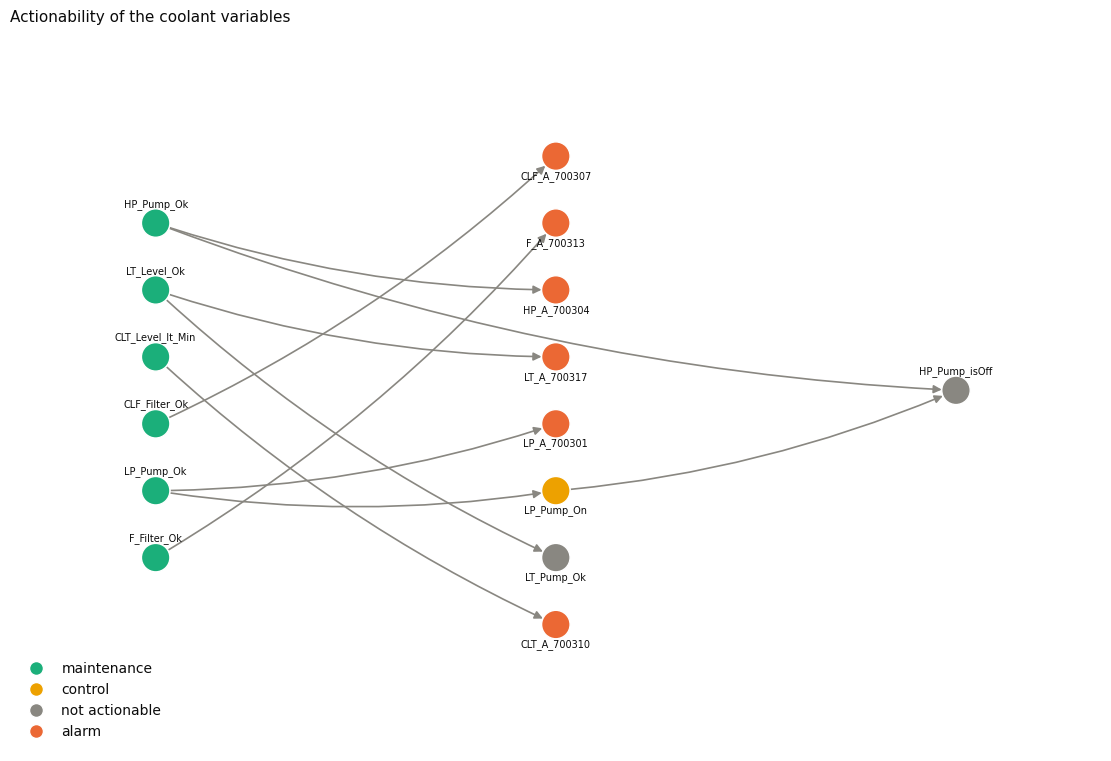

In [4]:
# figure 1: actionable variables on the expert graph
kind_colors = {'maintenance': ev.COLORS[2], 'control': ev.COLORS[3], 'not actionable': ev.INK['muted'], 'alarm': ev.COLORS[1]}
kind_of = actionability.set_index('variable').kind.to_dict()
fig, ax = plt.subplots(figsize=(11, 7.5), layout='constrained')
layout = ev.graph_layout(expert)
ev.draw_graph(expert, ax, node_types={}, pos=layout, title='Actionability of the coolant variables')
nx.draw_networkx_nodes(expert, layout, nodelist=NODES, ax=ax, node_size=420,
                       node_color=[kind_colors[kind_of[n]] for n in NODES], edgecolors=ev.INK['surface'])
ax.legend(handles=[plt.Line2D([], [], marker='o', linestyle='', markersize=10, markerfacecolor=c,
                              markeredgecolor=ev.INK['surface'], label=k) for k, c in kind_colors.items()], loc='lower left')
ev.save_figure(fig, f'07_{SUBSYSTEM}_actionability')
plt.show()

In [5]:
# feasibility checks on example intervention requests
requests = [
    [itv.Action('CLF_Filter_Ok', 1.0, 10)],
    [itv.Action('HP_Pump_Ok', 1.0, 10), itv.Action('LT_Level_Ok', 1.0, 10)],
    [itv.Action('CLT_Level_lt_Min', 0.0, 10)],
    [itv.Action('LP_Pump_On', 0.0, 10)],
    [itv.Action('HP_Pump_Ok', 0.0, 10)],
    [itv.Action('HP_A_700304', 0.0, 10)],
    [itv.Action('HP_Pump_isOff', 0.0, 10)],
    [itv.Action('CLF_Filter_Ok', 1.0, 10), itv.Action('F_Filter_Ok', 1.0, 10), itv.Action('LP_Pump_Ok', 1.0, 10),
     itv.Action('HP_Pump_Ok', 1.0, 10)],
]
feasibility = pd.DataFrame([{'request': ' + '.join(f'do({a.variable}={a.value:g})' for a in r),
                             'feasible': itv.check_feasibility(r)[0], 'problems': '; '.join(itv.check_feasibility(r)[1])}
                            for r in requests])
ev.save_table(feasibility, f'07_{SUBSYSTEM}_feasibility_examples')
feasibility

,request,feasible,problems
0,do(CLF_Filter_Ok=1),True,
1,do(HP_Pump_Ok=1) + do(LT_Level_Ok=1),True,
2,do(CLT_Level_lt_Min=0),True,
3,do(LP_Pump_On=0),True,
4,do(HP_Pump_Ok=0),False,HP_Pump_Ok may only be set to 1
5,do(HP_A_700304=0),False,HP_A_700304 is not actionable
6,do(HP_Pump_isOff=0),False,HP_Pump_isOff is not actionable
7,do(CLF_Filter_Ok=1) + do(F_Filter_Ok=1) + do(L...,False,more than 3 actions


## 2. Predicted effects of every actionable variable

The SCMs here are fitted on **all** training data (normal training recordings and all coolant fault runs), so this section describes the fitted models rather than testing them. The held-out test is in section 3.

For each actionable variable the machine starts in its usual (healthy) state and is simulated for 120 s twice:
- maintenance variables: do(faulty value) and do(healthy value). From a healthy start, do(healthy) means the component stays healthy, so the effect measures introducing the fault, not repairing it
- the control command: do(1) and do(0)

The effect is the difference in the probability that an outcome has left its usual state at the end of the horizon.

In [6]:
# predicted effect matrices per graph
full_train = data.fold_training_ids(splits, held_out=None)
full_scms = {g: sc.fit_scm(view_data, getter(None), full_train, manipulated, INTERVAL) for g, getter in graph_getters.items()}
actionable_vars = actionability.loc[actionability.actionable, 'variable'].tolist()
outcomes = [n for n in NODES if n not in actionable_vars]
effects = pd.concat([itv.effect_matrix(m, actionable_vars, outcomes, int(HORIZON_S / INTERVAL), N_SAMPLES,
                                       np.random.default_rng(SEED)).assign(graph=g) for g, m in full_scms.items()],
                    ignore_index=True)
ev.save_table(effects, f'07_{SUBSYSTEM}_effect_matrix')
effects.pivot_table(index=['variable', 'outcome'], columns='graph', values='effect').round(2).loc[lambda d: d.abs().max(axis=1) > 0.05]

graph                           discovered  empty  expert
variable         outcome                                 
CLF_Filter_Ok    CLF_A_700307         1.00   0.03    1.00
                 LT_A_700317          0.07   0.07    0.01
CLT_Level_lt_Min CLT_A_700310         1.00  -0.03    0.99
                 HP_Pump_isOff       -0.01  -0.01   -0.07
F_Filter_Ok      F_A_700313           0.99  -0.01    0.99
                 LT_A_700317         -0.07  -0.07    0.01
HP_Pump_Ok       F_A_700313          -0.01  -0.06   -0.00
                 HP_A_700304          1.00  -0.02    0.99
                 HP_Pump_isOff       -0.01   0.00    0.55
LP_Pump_Ok       F_A_700313          -0.01  -0.07   -0.00
                 HP_Pump_isOff       -0.01   0.03    0.09
                 LP_A_700301          1.00  -0.03    1.00
LP_Pump_On       HP_Pump_isOff       -0.39   0.02   -0.38
LT_Level_Ok      LT_A_700317          0.03   0.03    0.98
                 LT_Pump_Ok           0.01   0.01    0.94

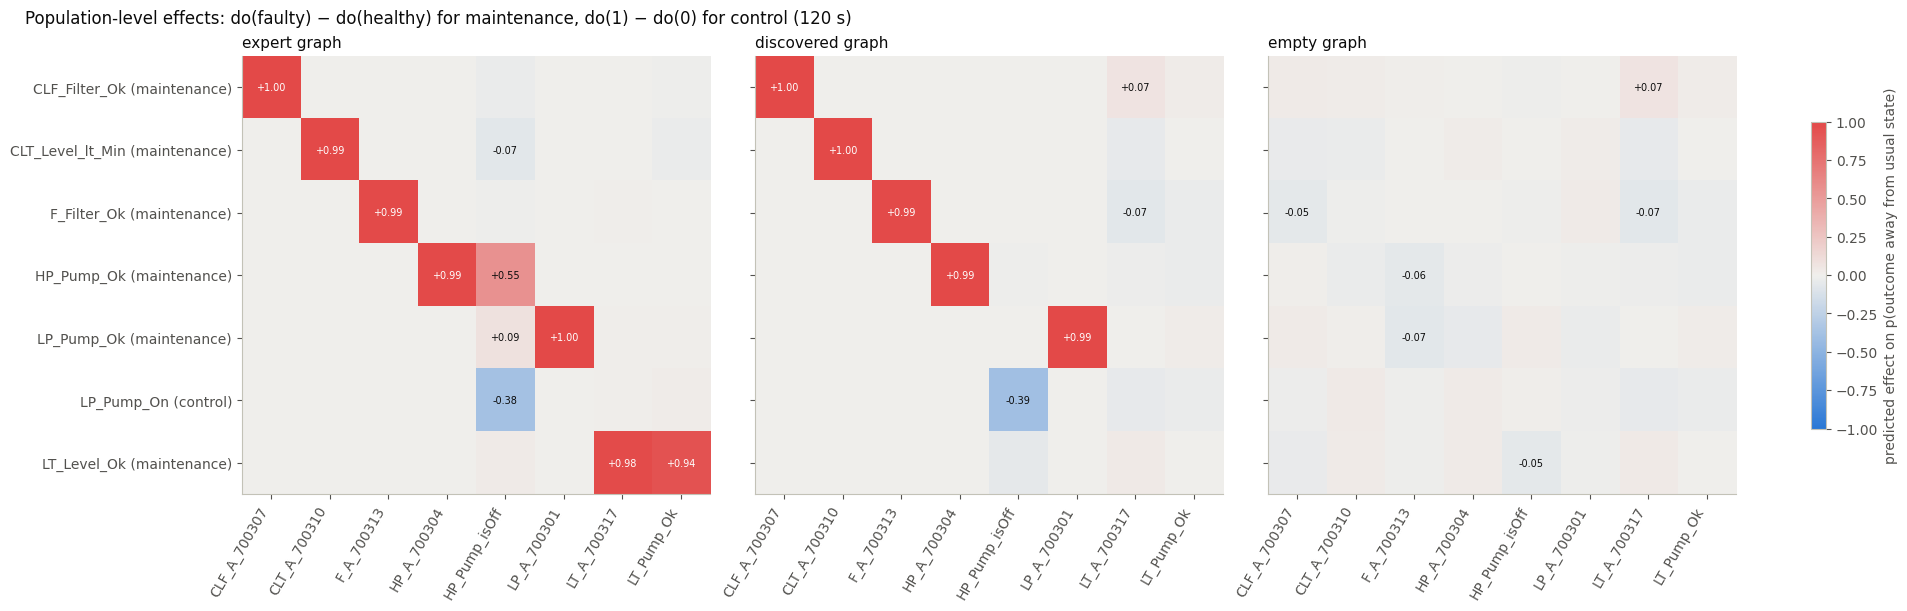

In [7]:
# figure 2: predicted effect of each actionable variable on each outcome, per graph
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True, layout='constrained')
diverging = LinearSegmentedColormap.from_list('diverging', [ev.COLORS[0], '#f0efec', '#e34948'])
for ax, g in zip(axes, graph_getters):
    m = effects[effects.graph == g].pivot(index='variable', columns='outcome', values='effect').reindex(index=actionable_vars, columns=outcomes)
    image = ax.imshow(m.to_numpy(dtype=float), cmap=diverging, vmin=-1, vmax=1, aspect='auto')
    for (i, j), v in np.ndenumerate(m.to_numpy(dtype=float)):
        if abs(v) >= 0.05:
            ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=7, color=ev.INK['surface'] if abs(v) > 0.6 else ev.INK['primary'])
    ax.set_xticks(range(len(outcomes)), outcomes, rotation=60, ha='right')
    ax.set_yticks(range(len(actionable_vars)), [f'{v} ({kind_of[v]})' for v in actionable_vars])
    ax.grid(False)
    ax.set_title(f'{g} graph')
fig.colorbar(image, ax=axes, shrink=0.7, label='predicted effect on p(outcome away from usual state)')
fig.suptitle('Population-level effects: do(faulty) − do(healthy) for maintenance, do(1) − do(0) for control (120 s)', x=0.01, ha='left')
ev.save_figure(fig, f'07_{SUBSYSTEM}_effect_matrix')
plt.show()

## 3. Do predicted effects match the real manipulations? (held-out test)

Every fault run is a real intervention: the digital twin set the root-cause variables to a faulty value. The replay therefore validates fault introduction and alarm propagation, not recovery after a repair. We replay exactly these manipulations, at their observed onset times and starting from the run's observed state, in an SCM fitted **without that scenario**. We then compare predicted and observed alarm responses. Alarms that the training scenarios never recorded have no mechanism estimate and are marked unsupported.

In [8]:
# replay of the observed manipulations in every held-out run
changes = data.fault_variable_changes(
    pp.mark_changes(pp.parse_values(pp.load_all_events(
        [r for r in pp.discover_recordings(data.RAW_DIR) if r.subsystem == SUBSYSTEM], data.RAW_DIR))),
    runs[runs.subsystem == SUBSYSTEM], experiments)
onset_steps = {(r, v): int(np.ceil(round(t / INTERVAL, 9))) for r, v, t in
               zip(changes.recording_id, changes.variable, changes.first_change_after_start_s) if not np.isnan(t)}

replay_rows = []
for fold in folds:
    for g, getter in graph_getters.items():
        model = sc.fit_scm(view_data, getter(fold), data.fold_training_ids(splits, fold), manipulated, INTERVAL)
        for rid in splits.loc[splits.fold == fold, 'recording_id']:
            series = sc.recording_series(view_data, rid)
            onsets = {v: onset_steps[(rid, v)] for v in manipulated[rid] if (rid, v) in onset_steps}
            result = itv.replay_manipulation(model, series, onsets, ALARMS, 200, np.random.default_rng(SEED))
            replay_rows.append(result.assign(graph=g, fold=fold, recording_id=rid))
replay = pd.concat(replay_rows, ignore_index=True)
replay['observed_delay_s'] = replay.observed_delay_steps * INTERVAL
replay['predicted_delay_s'] = replay.predicted_median_delay_steps * INTERVAL
ev.save_table(replay, f'07_{SUBSYSTEM}_replay')
replay.groupby(['graph', 'alarm_supported']).agg(pairs=('alarm', 'size'), observed_fired=('observed_fired', 'mean'),
                                                  mean_p_fires=('p_fires', 'mean')).round(3)

pairs  observed_fired  mean_p_fires
graph      alarm_supported                                     
discovered False               19             1.0         0.000
           True                37             1.0         1.000
empty      False               19             1.0         0.000
           True                37             1.0         0.496
expert     False               19             1.0         0.000
           True                37             1.0         1.000

In [9]:
# agreement per graph: firing probability and delay error on supported alarms
supported = replay[replay.alarm_supported & replay.observed_fired]
agreement = supported.groupby('graph').agg(
    pairs=('alarm', 'size'),
    mean_p_fires=('p_fires', 'mean'),
    share_p_fires_above_half=('p_fires', lambda p: (p > 0.5).mean()),
    median_abs_delay_error_s=('predicted_delay_s', lambda s: np.nanmedian(np.abs(s - supported.loc[s.index, 'observed_delay_s']))),
).reset_index()
ev.save_table(agreement, f'07_{SUBSYSTEM}_replay_agreement')
agreement.round(3)

,graph,pairs,mean_p_fires,share_p_fires_above_half,median_abs_delay_error_s
0,discovered,37,1.000,1.000,0.5
1,empty,37,0.496,0.514,41.5
2,expert,37,1.000,1.000,0.5


In [10]:
# delay error per alarm: the overall median can hide alarms whose delay is longer than one step
per_alarm = (supported.assign(abs_error_s=lambda d: (d.predicted_delay_s - d.observed_delay_s).abs())
             .groupby(['graph', 'alarm'])
             .agg(pairs=('alarm', 'size'), observed_delay_s=('observed_delay_s', 'median'),
                  predicted_delay_s=('predicted_delay_s', 'median'), median_abs_error_s=('abs_error_s', 'median'))
             .reset_index())
ev.save_table(per_alarm, f'07_{SUBSYSTEM}_replay_delay_per_alarm')
per_alarm.round(2)

,graph,alarm,pairs,observed_delay_s,predicted_delay_s,median_abs_error_s
0,discovered,CLF_A_700307,12,5.5,3.00,2.00
1,discovered,HP_A_700304,13,13.0,13.00,0.00
2,discovered,LP_A_700301,12,35.5,35.50,0.00
3,empty,CLF_A_700307,12,5.5,56.00,50.62
4,empty,HP_A_700304,13,13.0,40.00,24.75
5,empty,LP_A_700301,12,35.5,52.38,12.38
6,expert,CLF_A_700307,12,5.5,3.00,2.00
7,expert,HP_A_700304,13,13.0,13.00,0.00
8,expert,LP_A_700301,12,35.5,35.50,0.00


In [11]:
# what the replay can and cannot test: observed outcomes, horizon length, premature or late onsets
horizon_s = {}
for rid in replay.recording_id.unique():
    first = min(onset_steps[(rid, v)] for v in manipulated[rid] if (rid, v) in onset_steps)
    horizon_s[rid] = (len(next(iter(sc.recording_series(view_data, rid).values()))) - (first - 1)) * INTERVAL
h = pd.Series(horizon_s)
print(f'replayed runs: {len(h)} | simulation horizon (rest of the run): {h.min():.1f} - {h.max():.1f} s')
timing = supported.assign(premature=supported.predicted_delay_s < supported.observed_delay_s - INTERVAL,
                          late=supported.predicted_delay_s > supported.observed_delay_s + INTERVAL,
                          never_predicted=supported.predicted_delay_s.isna())
scope = replay.groupby('graph').agg(alarm_run_pairs=('alarm', 'size'), observed_fired=('observed_fired', 'sum'),
                                    supported=('alarm_supported', 'sum'))
scope['observed_not_fired'] = scope.alarm_run_pairs - scope.observed_fired
scope = scope.join(timing.groupby('graph')[['premature', 'late', 'never_predicted']].sum())
ev.save_table(scope.reset_index(), f'07_{SUBSYSTEM}_replay_scope')
scope

replayed runs: 25 | simulation horizon (rest of the run): 79.0 - 196.5 s


,alarm_run_pairs,observed_fired,supported,observed_not_fired,premature,late,never_predicted
graph,,,,,,,
discovered,56,56,37,0,12,0,0
empty,56,56,37,0,0,37,0
expert,56,56,37,0,12,0,0


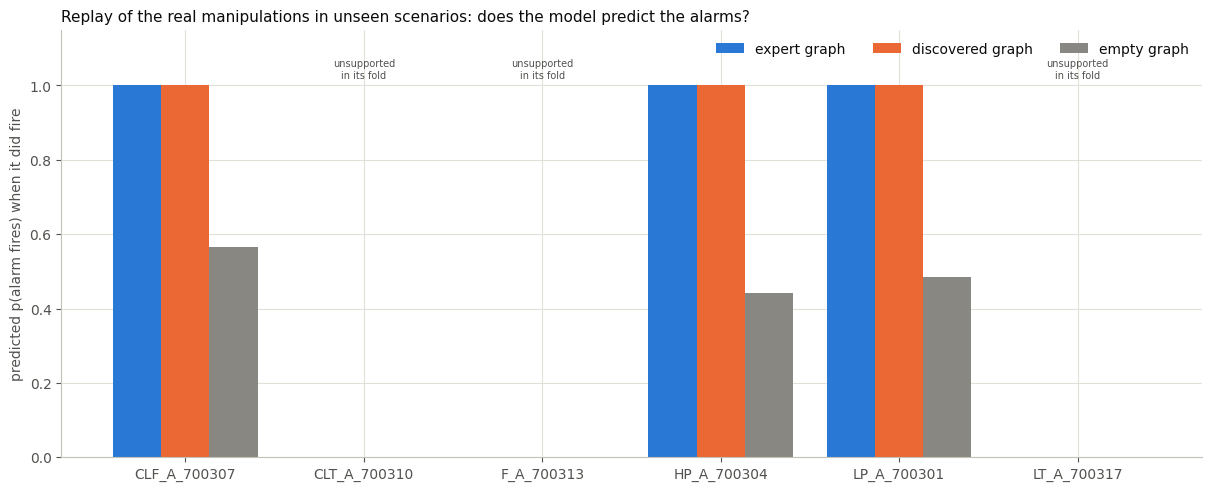

In [12]:
# figure 3: predicted firing probability of the observed alarms, per alarm and graph
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
alarm_order = sorted(replay.alarm.unique())
x = np.arange(len(alarm_order))
for k, g in enumerate(graph_getters):
    d = replay[(replay.graph == g) & replay.observed_fired].groupby('alarm').p_fires.mean().reindex(alarm_order)
    ax.bar(x + (k - 1) * 0.27, d, width=0.27, color=graph_colors[g], label=f'{g} graph')
for xi, a in zip(x, alarm_order):
    if not replay.loc[(replay.alarm == a) & (replay.graph == 'expert'), 'alarm_supported'].all():
        ax.text(xi, 1.02, 'unsupported\nin its fold', ha='center', fontsize=7, color=ev.INK['secondary'])
ax.set_xticks(x, alarm_order)
ax.set_ylim(0, 1.15)
ax.set_ylabel('predicted p(alarm fires) when it did fire')
ax.set_title('Replay of the real manipulations in unseen scenarios: does the model predict the alarms?')
ax.legend(loc='upper right', ncol=3)
ev.save_figure(fig, f'07_{SUBSYSTEM}_replay_firing')
plt.show()

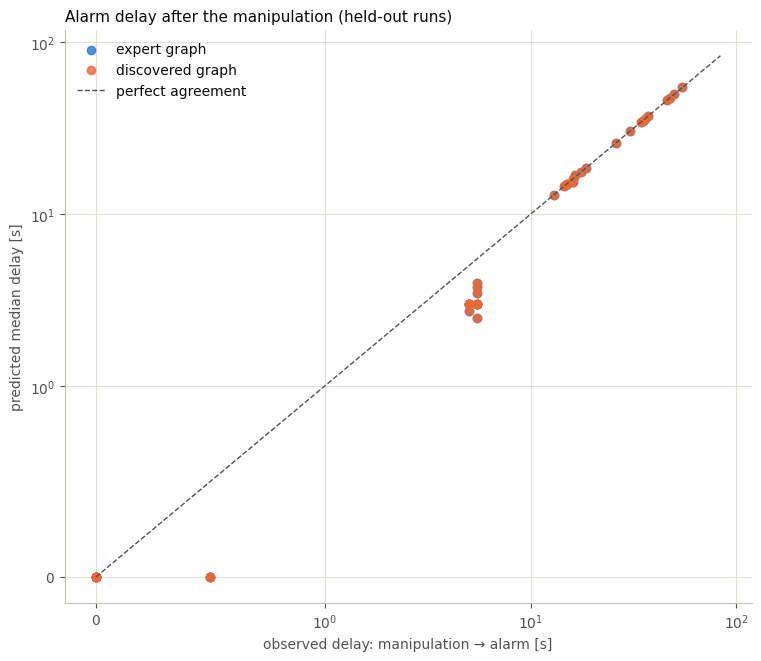

In [13]:
# figure 4: observed vs predicted alarm delay (supported alarms, expert and discovered graphs)
fig, ax = plt.subplots(figsize=(7.5, 6.5), layout='constrained')
for g in ['expert', 'discovered']:
    d = replay[(replay.graph == g) & replay.alarm_supported & replay.observed_fired]
    ax.scatter(d.observed_delay_s, d.predicted_delay_s, s=36, color=graph_colors[g], alpha=0.8, label=f'{g} graph')
lim = np.nanmax([replay.observed_delay_s.max(), replay.predicted_delay_s.max(), 10]) * 1.1
ax.plot([0, lim], [0, lim], color=ev.INK['secondary'], linestyle='--', linewidth=1, label='perfect agreement')
ax.set_xscale('symlog', linthresh=1)
ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel('observed delay: manipulation → alarm [s]')
ax.set_ylabel('predicted median delay [s]')
ax.set_title('Alarm delay after the manipulation (held-out runs)')
ax.legend(loc='upper left')
ev.save_figure(fig, f'07_{SUBSYSTEM}_replay_delays')
plt.show()

## 4. Example intervention analysis

What does the model predict when the fine filter clogs at t = 5 s, and how does that depend on the graph? The curves show the share of simulated runs in which each alarm is active.

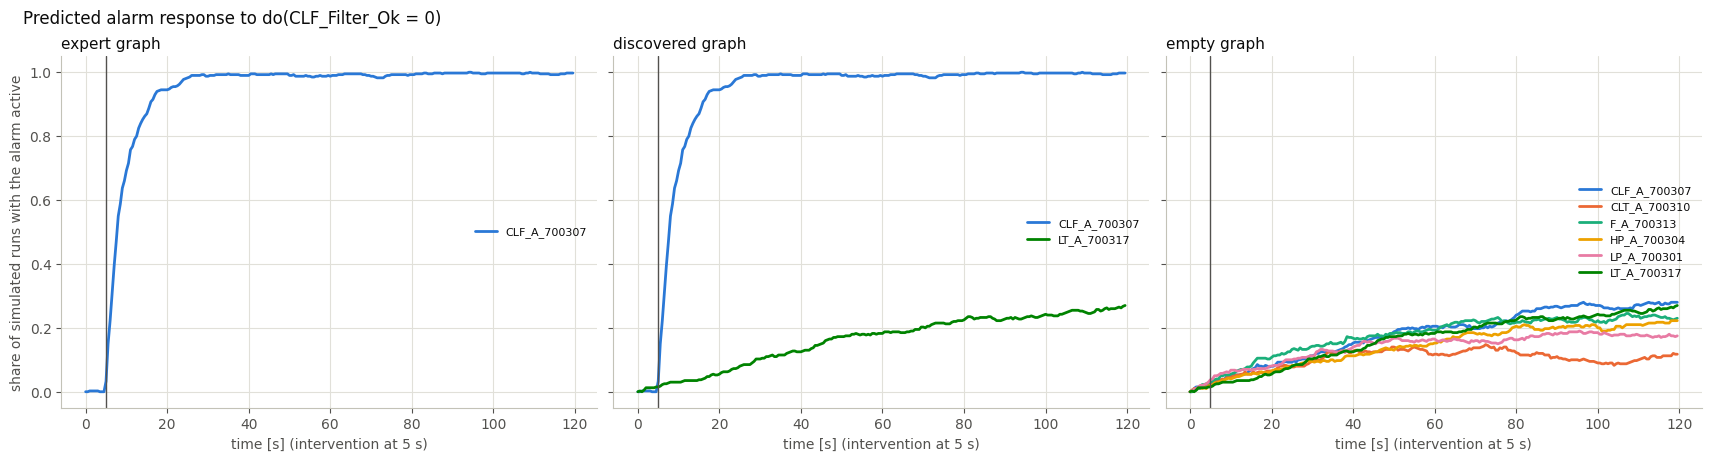

In [14]:
# figure 5: alarm activation over time after do(CLF_Filter_Ok = 0), per graph
example_var, example_value = 'CLF_Filter_Ok', 0.0
steps = int(HORIZON_S / INTERVAL)
t = np.arange(steps) * INTERVAL
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True, layout='constrained')
for ax, (g, model) in zip(axes, full_scms.items()):
    initial = {v: model.fills[v] for v in model.mechanisms}
    sim = itv.simulate_from_state(model, initial, steps, N_SAMPLES, np.random.default_rng(SEED),
                                  interventions={example_var: (example_value, int(5 / INTERVAL))})
    for k, a in enumerate(ALARMS):
        share = sim[a].mean(axis=0)
        if share.max() > 0.02:
            ax.plot(t, share, color=ev.COLORS[k % len(ev.COLORS)], label=a)
    ax.axvline(5, color=ev.INK['secondary'], linewidth=1)
    ax.set_xlabel('time [s] (intervention at 5 s)')
    ax.set_title(f'{g} graph')
    ax.legend(loc='center right', fontsize=8)
axes[0].set_ylabel('share of simulated runs with the alarm active')
fig.suptitle(f'Predicted alarm response to do({example_var} = {example_value:g})', x=0.01, ha='left')
ev.save_figure(fig, f'07_{SUBSYSTEM}_example_intervention')
plt.show()

## 5. Temporal extension: lag-aware discovered SCM

The first-order SCM predicts the filter alarm about 2 s too early, because a fixed 5 s delay becomes a constant switching hazard. The lag-aware SCM is a temporal extension of the primary first-order framework. It adds the discovered lags (selected per fold in notebook 05, table `05_coolant_lag_selection`) to the discovered graph only. Both models are reported side by side.

**Replay setup.**
- The replay starts mid-recording, so the observed states before its start are passed as history. Lagged parents read the real past there; padding with the start state is used only where no history exists.
- Both models use the same held-out runs, the same replayed manipulations and the same random numbers. Differences are therefore paired.

In [15]:
# lag-aware discovered scms (fold-specific lags from notebook 05) and their replay of the held-out manipulations
lag_table = pd.read_csv(tables / f'05_{SUBSYSTEM}_lag_selection.csv')
chosen = lag_table[lag_table.decision == 'selected']
lag_sets = {gid: {(u, v): tuple(sorted(g.lag)) for (u, v), g in chosen[chosen.graph_id == gid].groupby(['source', 'target'])}
            for gid in edges.graph_id.unique()}
lag_rows = []
for fold in folds:
    gid = f'discovered_without_{fold}'
    model = sc.fit_scm(view_data, discovered_dag[gid], data.fold_training_ids(splits, fold), manipulated, INTERVAL, lags=lag_sets[gid])
    for rid in splits.loc[splits.fold == fold, 'recording_id']:
        series = sc.recording_series(view_data, rid)
        onsets = {v: onset_steps[(rid, v)] for v in manipulated[rid] if (rid, v) in onset_steps}
        result = itv.replay_manipulation(model, series, onsets, ALARMS, 200, np.random.default_rng(SEED))
        lag_rows.append(result.assign(graph='discovered + lags', fold=fold, recording_id=rid))
replay_lagged = pd.concat(lag_rows, ignore_index=True)
replay_lagged['observed_delay_s'] = replay_lagged.observed_delay_steps * INTERVAL
replay_lagged['predicted_delay_s'] = replay_lagged.predicted_median_delay_steps * INTERVAL
ev.save_table(replay_lagged, f'07_{SUBSYSTEM}_replay_lagged')
print({gid: {f'{u} -> {v}': [l * INTERVAL for l in ls] for (u, v), ls in s.items()} for gid, s in lag_sets.items() if gid != 'discovered'})

{'discovered_without_exp_22': {'CLF_Filter_Ok -> CLF_A_700307': [5.0, 5.5], 'CLT_Level_lt_Min -> CLT_A_700310': [1.0], 'F_Filter_Ok -> F_A_700313': [5.0]}, 'discovered_without_exp_27': {'CLF_Filter_Ok -> CLF_A_700307': [5.0, 5.5], 'F_Filter_Ok -> F_A_700313': [5.0]}, 'discovered_without_exp_28': {'CLF_Filter_Ok -> CLF_A_700307': [5.5], 'CLT_Level_lt_Min -> CLT_A_700310': [1.0]}, 'discovered_without_exp_35': {'CLF_Filter_Ok -> CLF_A_700307': [5.0], 'CLT_Level_lt_Min -> CLT_A_700310': [1.0], 'F_Filter_Ok -> F_A_700313': [5.0]}}


In [16]:
# first-order vs lag-aware on identical (run, alarm) pairs: firing, delay error, premature and late onsets
both = pd.concat([replay[replay.graph.isin(['discovered', 'empty'])], replay_lagged], ignore_index=True)
both = both[both.alarm_supported & both.observed_fired].assign(
    abs_error_s=lambda d: (d.predicted_delay_s - d.observed_delay_s).abs(),
    premature=lambda d: d.predicted_delay_s < d.observed_delay_s - INTERVAL,
    late=lambda d: d.predicted_delay_s > d.observed_delay_s + INTERVAL)
lag_replay = both.groupby(['alarm', 'graph']).agg(
    folds=('fold', 'nunique'), recordings=('recording_id', 'nunique'), pairs=('alarm', 'size'),
    observed_delay_s=('observed_delay_s', 'median'), predicted_delay_s=('predicted_delay_s', 'median'),
    median_abs_error_s=('abs_error_s', 'median'), mean_abs_error_s=('abs_error_s', 'mean'),
    mean_p_fires=('p_fires', 'mean'), premature=('premature', 'sum'), late=('late', 'sum')).reset_index()
ev.save_table(lag_replay, f'07_{SUBSYSTEM}_replay_lag_comparison')
key = ['recording_id', 'alarm']
pair = both[both.graph == 'discovered'].merge(both[both.graph == 'discovered + lags'], on=key, suffixes=('_first', '_lagged'))
for a, d in pair.groupby('alarm'):
    gain = d.abs_error_s_first - d.abs_error_s_lagged
    print(f'{a}: {len(d)} paired runs, delay error first-order minus lag-aware: mean {gain.mean():+.2f} s, '
          f'better/worse/same {int((gain > 0).sum())}/{int((gain < 0).sum())}/{int((gain == 0).sum())}')
lag_replay.round(3)

CLF_A_700307: 12 paired runs, delay error first-order minus lag-aware: mean +1.79 s, better/worse/same 12/0/0
HP_A_700304: 13 paired runs, delay error first-order minus lag-aware: mean +0.00 s, better/worse/same 0/0/13
LP_A_700301: 12 paired runs, delay error first-order minus lag-aware: mean +0.00 s, better/worse/same 0/0/12


,alarm,graph,folds,recordings,pairs,observed_delay_s,predicted_delay_s,median_abs_error_s,mean_abs_error_s,mean_p_fires,premature,late
0,CLF_A_700307,discovered,2,12,12,5.5,3.000,2.000,2.167,1.000,12,0
1,CLF_A_700307,discovered + lags,2,12,12,5.5,5.250,0.500,0.375,1.000,0,0
2,CLF_A_700307,empty,2,12,12,5.5,56.000,50.625,49.854,0.565,0,12
3,HP_A_700304,discovered,2,13,13,13.0,13.000,0.000,0.115,1.000,0,0
4,HP_A_700304,discovered + lags,2,13,13,13.0,13.000,0.000,0.115,1.000,0,0
5,HP_A_700304,empty,2,13,13,13.0,40.000,24.750,43.346,0.443,0,13
6,LP_A_700301,discovered,2,12,12,35.5,35.500,0.000,0.167,1.000,0,0
7,LP_A_700301,discovered + lags,2,12,12,35.5,35.500,0.000,0.167,1.000,0,0
8,LP_A_700301,empty,2,12,12,35.5,52.375,12.375,16.750,0.484,0,12


In [17]:
# does the observed history matter? lagged parents that change in the lag window before the replay start
hist_rows = []
for rid in replay_lagged.recording_id.unique():
    series = sc.recording_series(view_data, rid)
    t0 = min(onset_steps[(rid, v)] for v in manipulated[rid] if (rid, v) in onset_steps) - 1
    for (u, v), ls in lag_sets['discovered'].items():
        if u not in series or np.isnan(series[u]).all():
            continue
        window = series[u][max(0, t0 - max(ls)):t0 + 1]
        hist_rows.append({'recording_id': rid, 'parent': u, 'history_steps_available': t0,
                          'changes_in_lag_window': int(np.count_nonzero(np.diff(window[~np.isnan(window)])))})
history_check = pd.DataFrame(hist_rows)
print('replays whose lagged parent changes inside the lag window before the start:',
      int((history_check.changes_in_lag_window > 0).sum()), 'of', len(history_check),
      '| history steps available: min', int(history_check.history_steps_available.min()))

replays whose lagged parent changes inside the lag window before the start: 0 of 25 | history steps available: min 175


In [18]:
# predicted onset after do(faulty) from the healthy state (full-data scms, descriptive): delay distribution and off-target alarms
steps = int(HORIZON_S / INTERVAL)
lagged_full = sc.fit_scm(view_data, discovered_dag['discovered'], full_train, manipulated, INTERVAL, lags=lag_sets['discovered'])
variants = {'discovered': full_scms['discovered'], 'discovered + lags': lagged_full}
targets = {'CLF_Filter_Ok': 'CLF_A_700307', 'F_Filter_Ok': 'F_A_700313', 'CLT_Level_lt_Min': 'CLT_A_700310'}
onset_rows = []
for name, model in variants.items():
    initial = {v: model.fills[v] for v in model.mechanisms}
    for cause, alarm in targets.items():
        faulty = 1.0 - itv.allowed_value(cause)
        sim = itv.simulate_from_state(model, initial, steps, N_SAMPLES, np.random.default_rng(SEED), {cause: (faulty, 1)})
        delay = (itv.first_activation(sim[alarm], start=1) - 1) * INTERVAL
        off_target = [a for a in ALARMS if a != alarm and a not in nx.descendants(expert, cause)]
        onset_rows.append({'variant': name, 'intervention': f'do({cause}={faulty:g})', 'alarm': alarm,
                           'p_fires': float(np.mean(~np.isnan(delay))), 'median_delay_s': float(np.nanmedian(delay)),
                           'iqr_low_s': float(np.nanpercentile(delay, 25)), 'iqr_high_s': float(np.nanpercentile(delay, 75)),
                           'p_off_target_alarm': float(np.mean([np.any(sim[a][:, 1:] == 1, axis=1).mean() for a in off_target]))})
intervention_onsets = pd.DataFrame(onset_rows)
ev.save_table(intervention_onsets, f'07_{SUBSYSTEM}_intervention_onsets_lagged')
intervention_onsets.round(3)

,variant,intervention,alarm,p_fires,median_delay_s,iqr_low_s,iqr_high_s,p_off_target_alarm
0,discovered,do(CLF_Filter_Ok=0),CLF_A_700307,1.0,3.5,1.5,6.5,0.112
1,discovered,do(F_Filter_Ok=0),F_A_700313,1.0,3.0,1.0,6.0,0.112
2,discovered,do(CLT_Level_lt_Min=1),CLT_A_700310,1.0,1.0,0.5,1.5,0.112
3,discovered + lags,do(CLF_Filter_Ok=0),CLF_A_700307,1.0,5.0,5.0,5.5,0.114
4,discovered + lags,do(F_Filter_Ok=0),F_A_700313,1.0,5.0,5.0,5.0,0.112
5,discovered + lags,do(CLT_Level_lt_Min=1),CLT_A_700310,1.0,1.0,1.0,1.0,0.114


## 6. Findings

- **Feasibility rules work as intended.**
  - Maintenance actions towards the healthy value and the pump command are accepted.
  - Breaking a component, setting an alarm, setting a derived feedback state, or more than three actions are rejected with a reason.
- **Predicted effects** (figure 2; SCMs fitted on all data, so descriptive):
  - With the **expert graph** every maintenance variable has its expected effect: do(faulty) − do(healthy) from the healthy state (fault introduction) raises the probability of its own alarm by 0.98–1.00. `HP_Pump_Ok` also switches the HP pump off (+0.55), `LT_Level_Ok` stops the lifting pump (+0.94), and starting the LP pump switches the HP pump on (−0.38).
  - The **discovered graph** reproduces the five cause → alarm effects and the pump interaction. It loses the effects that hinge on its missed or unoriented edges: `LT_Level_Ok` on its alarm and pump, and `HP_Pump_Ok` on `HP_Pump_isOff`.
  - The **empty graph** predicts no effect of any action (|effect| ≤ 0.07, noise only).
- **Agreement with the real manipulations** (held-out scenarios, 37 supported alarm activations, 19 unsupported):

  | Graph | Mean predicted p(alarm fires) when it did fire | Median delay error |
  |---|---|---|
  | expert | 1.00 | 0.5 s (one grid step) |
  | discovered | 1.00 | 0.5 s |
  | empty | 0.50 (fires at random times) | 41.5 s |

  The 19 unsupported activations are alarms whose only recording scenario was held out. They cannot be predicted by any graph and are reported, not hidden.
- **The overall median delay error hides a difference between alarms** (per-alarm table):
  - `HP_A_700304` and `LP_A_700301` fire in the same step as the visible change of their cause. Their delays are predicted exactly with both structured graphs (error 0.0 s, 25 activations).
  - The filter alarm `CLF_A_700307` fires a fixed 5–5.5 s after its cause. Both graphs predict it after 3.0 s (median error 2.0 s, 12 activations).
  - The cause is the SCM, not the graph. Mechanisms use parents only at lag 0 and 1, so a fixed 10-step delay becomes a constant switching hazard. PCMCI+ found the 5 s lag (notebook 03), but the first-order SCM cannot use it.
  - Whether the alarm *fires* is predicted correctly; only its timing is approximate.
- **What the replay can and cannot test** (scope table):
  - Every recorded alarm fired in every run: 56 positive outcomes per graph and **no observed non-firing case**. Firing agreement therefore cannot reveal over-prediction, and false alarm activations cannot be measured. Normal recordings do not record the alarms either.
  - The simulation horizon is the rest of each run (79–196.5 s), so the firing probability of a constant-hazard mechanism (empty graph) grows with run length.
  - The manipulations are replayed at their observed times. For alarms that react in the same step, the delay check therefore tests the immediate cause → alarm response, not longer propagation chains.
  - Timing errors are reported as premature or late predicted onsets (more than one step off). With the structured graphs these are the 12 filter-alarm activations, all predicted too early.
- **Temporal extension: lag-aware SCM (section 5)**, reported next to the primary first-order SCM.
  - **Filter alarm `CLF_A_700307`** (12 paired held-out runs, 2 folds):
    - median delay error 2.0 → 0.5 s (mean 2.17 → 0.38 s);
    - predicted median onset 5.25 s against 5.5 s observed;
    - better in 12 of 12 runs, premature onsets 12 → 0;
    - firing probability stays 1.00.
  - **Alarms without extra lags** (`HP_A_700304`, `LP_A_700301`) are unchanged (error 0.0 s).
  - **Interventions from the healthy state:**
    - do(`CLF_Filter_Ok` = 0) now fires the alarm after 5.0 s (IQR 5.0–5.5) instead of 3.5 s (IQR 1.5–6.5);
    - do(`F_Filter_Ok` = 0) after 5.0 s instead of 3.0 s;
    - the probability that some other alarm fires is unchanged (0.112 → 0.114).
  - **History.** The replay passes the observed pre-start states. In all 25 replays the lagged parents were constant in the lag window before the start, so history and start-state padding coincide here; the history code path is checked by unit tests.
  - **Still not measurable:** false alarm activations, because there is no observed non-firing case.
- **Example** (figure 5): after do(`CLF_Filter_Ok` = 0), both structured graphs predict the filter alarm in almost every simulated run, 5–15 s later. The spread is the constant-hazard approximation; the real delay is a fixed 5–5.5 s. With the discovered graph, `LT_A_700317` also drifts up to 0.27 within 120 s. Its cause edge was missed, so its mechanism has no parent and fires at a constant background rate, exactly like every alarm under the empty graph. This is a missing edge turning into a false alarm prediction.
- *Thesis note:*
  - This is the only test of the SCM's **interventional** predictions against real (fault-introducing) interventions, within a limited scope:
    - The digital-twin manipulations are real interventions on held-out scenarios, and the predicted alarm firing matches them. All observed outcomes are positive, so this shows the alarms are predicted to fire, not that false alarms are avoided.
    - It validates fault propagation. It does not validate recovery after repairing an already failed component.
    - The delays match for alarms that follow their cause within one step.
    - The 5 s filter-alarm delay is predicted about 2 s too early, a limitation of the first-order mechanisms.
  - It is also where graph quality starts to matter: what the graph misses, the intervention model cannot predict.
  - All effects remain model-predicted for the simulated machine; nothing here shows prevention on the real lathe.